[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ivanvladimir/maquinas_notebooks/blob/main/lfya/08%20Maquinas%20con%20cinta.ipynb)

# 09 Máquinas con cinta

Esta notebook ilustra los conceptos de [**Máquinas de Turing**](https://ivanvladimir.gitlab.io/lfya_book/docs/08lam%C3%A1quinaconcinta/) correspondiente al curso de [**Lenguajes Formales y Autómatas**](https://turing.iimas.unam.mx/~ivanvladimir/page/curso_lfya/)


## Instrucciones

1. Si la librería [**maquinas**](https://pypi.org/project/maquinas/) no está instalada ejecutar la celdas correspondiente a la sección marcada con ◉
2. Importar los módulos de librería relevantes
3. Ejecuar las celdas para explorar los conceptos


## Licencia de la notebook

<a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Creative Commons License" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a>
</br>This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Creative Commons Attribution 4.0 International License</a>.

## General information

> **Author(s)**: <a href="https://twitter.com/ivanvladimir">@ivanvladimir</a></br>
> **Last updated**: 24/01/2023

### ◉ Instalando la librería 

Se instala la librería [maquinas](https://pypi.org/project/maquinas/)

**Requerido en colab**, _opcional en ambiente local a través de jupyter_

In [ ]:
# Execute if not installes
!pip install maquinas --upgrade

### 01 Importar módulos

Se importan las [Máuring](https://ivanvladimir.gitlab.io/lfya_book/docs/07revisandolajerarqu%C3%ADadechomsky/05aut%C3%B3matadedoblepila/) (TM)

In [1]:
from maquinas.recursivelyenumerable.tm import TuringMachine as TM
from maquinas.simulation import Simulation
from maquinas.io import load_tm

In [2]:
# Creating automata finito
aⁿbⁿ=TM(Q=['q_0','q_1','q_2','q_3','q_4'],
         sigma=['a','b'],
         gamma=['X','Y'],
         q_0='q_0',
         A=['q_4'],
         delta=[
            (('q_0','a'),[('q_1','X','R')]),
            (('q_1','a'),[('q_1','a','R')]),
            (('q_1','Y'),[('q_1','Y','R')]),
            (('q_1','b'),[('q_2','Y','L')]),
            (('q_2','Y'),[('q_2','Y','L')]),
            (('q_2','a'),[('q_2','a','L')]),
            (('q_2','X'),[('q_0','X','R')]),
            (('q_0','Y'),[('q_3','Y','R')]),
            (('q_3','Y'),[('q_3','Y','R')]),
            (('q_3','[B]'),[('q_4','[B]','L')]),
         ]
    )
aⁿbⁿ.print_summary()

States  : q_0, q_1, q_2, q_3, q_4
Sigma   : a, b
Gamma   : 𝖁, X, Y, a, b
Initial : q_0
Aceptors: {q_4}
Transitions:
 q_0,a/X → q_1:R
 q_0,Y/Y → q_3:R
 q_1,a/a → q_1:R
 q_1,Y/Y → q_1:R
 q_1,b/Y → q_2:L
 q_2,Y/Y → q_2:L
 q_2,a/a → q_2:L
 q_2,X/X → q_0:R
 q_3,Y/Y → q_3:R
 q_3,𝖁/𝖁 → q_4:L

In [3]:
aⁿbⁿ=load_tm("""
        |     𝖁     |     X     |     Y     |     a     |     b     |
 ->q_0  |           |           | Y/Y→q_3:R | a/X→q_1:R |           |
   q_1  |           |           | Y/Y→q_1:R | a/a→q_1:R | b/Y→q_2:L |
   q_2  |           | X/X→q_0:R | Y/Y→q_2:L | a/a→q_2:L |           |
   q_3  | 𝖁/𝖁→q_4:L |           | Y/Y→q_3:R |           |           |
   q_4] |           |           |           |           |           |
""")
aⁿbⁿ.print_summary()

States  : q_0, q_1, q_2, q_3, q_4
Sigma   : X, Y, a, b
Gamma   : 𝖁, X, Y, a, b
Initial : q_0
Aceptors: {q_4}
Transitions:
 q_0,Y/Y → q_3:R
 q_0,a/X → q_1:R
 q_1,Y/Y → q_1:R
 q_1,a/a → q_1:R
 q_1,b/Y → q_2:L
 q_2,X/X → q_0:R
 q_2,Y/Y → q_2:L
 q_2,a/a → q_2:L
 q_3,𝖁/𝖁 → q_4:L
 q_3,Y/Y → q_3:R

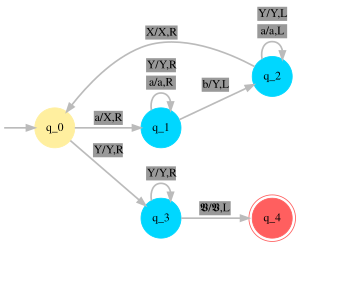

In [4]:
aⁿbⁿ.graph()

In [5]:
print(aⁿbⁿ.to_string(order_gamma=['a','b','X','Y','𝖁']))

        |     a     |     b     |     X     |     Y     |     𝖁     |
 ->q_0  | a/X→q_1:R |           |           | Y/Y→q_3:R |           |
   q_1  | a/a→q_1:R | b/Y→q_2:L |           | Y/Y→q_1:R |           |
   q_2  | a/a→q_2:L |           | X/X→q_0:R | Y/Y→q_2:L |           |
   q_3  |           |           |           | Y/Y→q_3:R | 𝖁/𝖁→q_4:L |
   q_4] |           |           |           |           |           |


In [6]:
aⁿbⁿ.save_animation("aaabbb",filename="anbn.apng",show=True)

In [7]:
aⁿbⁿ.table()

,𝖁,X,Y,a,b
⟶q_0,∅,∅,"Y,R→q_3","X,R→q_1",∅
q_1,∅,∅,"Y,R→q_1","a,R→q_1","Y,L→q_2"
q_2,∅,"X,R→q_0","Y,L→q_2","a,L→q_2",∅
q_3,"𝖁,L→q_4",∅,"Y,R→q_3",∅,∅
q_4,∅,∅,∅,∅,∅


In [8]:
for states in aⁿbⁿ.delta_stepwise("aaabbb"):
    if states:
        print(f"⊢ {aⁿbⁿ.states2string(states)}",end="\n")
        res=states
    else:
        print("Halts")

⊢ q_0, _a_ a a b b b
⊢ q_1, X _a_ a b b b
⊢ q_1, X a _a_ b b b
⊢ q_1, X a a _b_ b b
⊢ q_2, X a _a_ Y b b
⊢ q_2, X _a_ a Y b b
⊢ q_2, _X_ a a Y b b
⊢ q_0, X _a_ a Y b b
⊢ q_1, X X _a_ Y b b
⊢ q_1, X X a _Y_ b b
⊢ q_1, X X a Y _b_ b
⊢ q_2, X X a _Y_ Y b
⊢ q_2, X X _a_ Y Y b
⊢ q_2, X _X_ a Y Y b
⊢ q_0, X X _a_ Y Y b
⊢ q_1, X X X _Y_ Y b
⊢ q_1, X X X Y _Y_ b
⊢ q_1, X X X Y Y _b_
⊢ q_2, X X X Y _Y_ Y
⊢ q_2, X X X _Y_ Y Y
⊢ q_2, X X _X_ Y Y Y
⊢ q_0, X X X _Y_ Y Y
⊢ q_3, X X X Y _Y_ Y
⊢ q_3, X X X Y Y _Y_
⊢ q_3, X X X Y Y Y _𝖁_
⊢ q_4, X X X Y Y _Y_ 𝖁


In [ ]:
#aⁿbⁿ.save_gif("aaabb",filename="anbn_reject.gif",show=True)

### Sumando uno a numero binario

In [9]:
# Creating automata finito
suma_uno_binario=TM(Q=['q_0','q_1','q_s','q_f'],
         sigma=['0','1','$'],
         gamma=[],
         q_0='q_0',
         A=['q_f'],
         delta=[
            (('q_0','$'),[('q_1','$','R')]),
            (('q_1','1'),[('q_1','1','R')]), 
            (('q_1','0'),[('q_1','0','R')]),
            (('q_1','[B]'),[('q_s','[B]','L')]),
            (('q_s','1'),[('q_s','0','L')]),
            (('q_s','0'),[('q_f','1','R')]),
            (('q_s','$'),[('q_f','1','R')]),
         ]
    )

In [10]:
for states in suma_uno_binario.delta_stepwise("$1000011"):
    if states:
        print(f"⊢ {suma_uno_binario.states2string(states)}",end="\n")
        res=states
    else:
        print("Halts")

⊢ q_0, _$_ 1 0 0 0 0 1 1
⊢ q_1, $ _1_ 0 0 0 0 1 1
⊢ q_1, $ 1 _0_ 0 0 0 1 1
⊢ q_1, $ 1 0 _0_ 0 0 1 1
⊢ q_1, $ 1 0 0 _0_ 0 1 1
⊢ q_1, $ 1 0 0 0 _0_ 1 1
⊢ q_1, $ 1 0 0 0 0 _1_ 1
⊢ q_1, $ 1 0 0 0 0 1 _1_
⊢ q_1, $ 1 0 0 0 0 1 1 _𝖁_
⊢ q_s, $ 1 0 0 0 0 1 _1_ 𝖁
⊢ q_s, $ 1 0 0 0 0 _1_ 0 𝖁
⊢ q_s, $ 1 0 0 0 _0_ 0 0 𝖁
⊢ q_f, $ 1 0 0 0 1 _0_ 0 𝖁


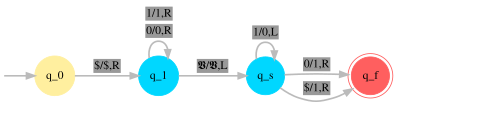

In [11]:
suma_uno_binario.graph()

### Multiplicación

In [12]:
a_n_b_m_c_nm=TM(Q=['q_0','q_1','q_2','q_3','q_4','q_5','q_6'],
         sigma=['0','1','$'],
         gamma=['X','Y'],
         q_0='q_0',
         A=['q_6'],
         delta=[
            (('q_0','a'),[('q_1','X','R')]),
            (('q_1','a'),[('q_1','a','R')]),
            (('q_1','b'),[('q_1','b','R')]),
            (('q_1','Y'),[('q_1','Y','R')]),
            (('q_1','c'),[('q_2','Y','L')]),
            (('q_2','a'),[('q_2','a','L')]),
            (('q_2','b'),[('q_2','b','L')]),
            (('q_2','Y'),[('q_2','Y','L')]),
            (('q_2','X'),[('q_0','X','R')]),
            (('q_0','b'),[('q_3','X','R')]),
            (('q_3','b'),[('q_3','b','R')]),
            (('q_3','Y'),[('q_3','Y','R')]),
            (('q_3','c'),[('q_4','Y','L')]),
            (('q_4','b'),[('q_4','b','L')]),
            (('q_4','Y'),[('q_4','Y','L')]),
            (('q_4','X'),[('q_0','X','R')]),
            (('q_0','Y'),[('q_5','Y','R')]),
            (('q_5','Y'),[('q_5','Y','R')]),
            (('q_5','[B]'),[('q_6','[B]','R')]),
            (('q_0','[B]'),[('q_6','[B]','R')]),
         ]
    )

In [13]:
for states in a_n_b_m_c_nm.delta_stepwise("bbcc"):
    if states:
        print(f"⊢ {a_n_b_m_c_nm.states2string(states)}",end="\n")
        res=states
    else:
        print("Halts")

print(f"\nCon {a_n_b_m_c_nm.states2string(res)} Se acepta?", "Sí" if a_n_b_m_c_nm.acceptor(res) else "No" )

⊢ q_0, _b_ b c c
⊢ q_3, X _b_ c c
⊢ q_3, X b _c_ c
⊢ q_4, X _b_ Y c
⊢ q_4, _X_ b Y c
⊢ q_0, X _b_ Y c
⊢ q_3, X X _Y_ c
⊢ q_3, X X Y _c_
⊢ q_4, X X _Y_ Y
⊢ q_4, X _X_ Y Y
⊢ q_0, X X _Y_ Y
⊢ q_5, X X Y _Y_
⊢ q_5, X X Y Y _𝖁_
⊢ q_6, X X Y Y 𝖁 _𝖁_

Con q_6, X X Y Y 𝖁 _𝖁_ Se acepta? Sí


In [14]:
a_n_b_m_c_nm.accepts("abcc")

True

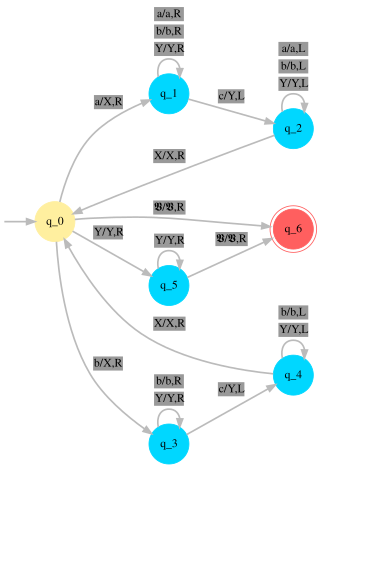

In [15]:
a_n_b_m_c_nm.graph()